In [2]:
import pandas as pd

df = pd.read_csv("spotify.csv")

df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

## Data Cleaning

In [11]:
# Check missing values
df.isnull().sum()

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [12]:
# Check duplicate rows
df.duplicated().sum()

np.int64(0)

In [13]:
# Check duplicate Spotify track IDs
df["track_id"].duplicated().sum()

np.int64(24259)

In [14]:
# Inspect rows with missing values
df[df.isnull().any(axis=1)]

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,...,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


In [15]:
# Inspect tracks appearing more than once
df[df["track_id"].duplicated(keep=False)].sort_values("track_id").head(10)

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
15028,15028,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,...,-6.644,0,0.1070,0.31600,0.000001,0.1170,0.406,143.064,4,chill
103211,103211,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,...,-6.644,0,0.1070,0.31600,0.000001,0.1170,0.406,143.064,4,soul
85578,85578,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,...,-4.589,1,0.0758,0.01940,0.088100,0.3290,0.700,183.571,1,punk-rock
100420,100420,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,...,-4.589,1,0.0758,0.01940,0.088100,0.3290,0.700,183.571,1,ska
91801,91801,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,...,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,rock
3257,3257,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,...,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,alternative
2106,2106,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,...,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,alt-rock
33178,33178,004h8smbIoAkUNDJvVKwkG,Ouse;Powfu,Loners Diary,Lovemark,58,219482,True,0.808,0.331,...,-13.457,1,0.0557,0.13100,0.000000,0.2250,0.337,140.035,4,emo
94239,94239,004h8smbIoAkUNDJvVKwkG,Ouse;Powfu,Loners Diary,Lovemark,58,219482,True,0.808,0.331,...,-13.457,1,0.0557,0.13100,0.000000,0.2250,0.337,140.035,4,sad
97533,97533,006rHBBNLJMpQs8fRC2GDe,Calcinha Preta;Gusttavo Lima,CP 25 Anos (Ao Vivo em Aracaju),Agora Estou Sofrendo - Ao Vivo,47,260510,False,0.605,0.678,...,-3.257,1,0.0311,0.64200,0.000000,0.1570,0.439,125.059,4,sertanejo


In [16]:
# Check how many genres each track appears in
df.groupby("track_id")["track_genre"].nunique().describe()

count    89741.000000
mean         1.265308
std          0.664204
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          9.000000
Name: track_genre, dtype: float64

### Cleaning Decisions

The dataset contains 114,000 rows and 21 columns. Only one row has missing values, specifically in the artists, album_name, and track_name columns. Since this represents a very small portion of the dataset, I decided to remove it.

The Unnamed: 0 column appears to be an unnecessary index and will also be removed.

In [17]:
# Create a cleaned copy of the dataset
df_clean = df.copy()

# Remove the unnecessary index column
df_clean = df_clean.drop(columns=["Unnamed: 0"])

# Remove the row with missing values
df_clean = df_clean.dropna(
    subset=["artists", "album_name", "track_name"]
)

# Check the resulting dataset
df_clean.shape

(113999, 20)

### Duplicate Track IDs

When I was exploring the dataset, I found 42,259 repeated track IDs, even though there were no completely duplicated rows. After analyzing some examples, I noticed that the same song could appear in different genres. For example, "Mr. Brightside" by The Killers appeared in multiple categories. Because of this, I decided to keep the repeated track IDs for now, since removing them could result in losing information about how songs are classified. However, these repetitions could affect future statistical analyses by giving some songs more weight than others.

## Summary Statistics

In [18]:
# Descriptive statistics for numerical columns
df_clean.describe()

,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,113999.000000,1.139990e+05,113999.000000,113999.000000,113999.000000,113999.000000,113999.000000,113999.000000,113999.000000,113999.000000,113999.000000,113999.000000,113999.000000,113999.000000
mean,33.238827,2.280312e+05,0.566801,0.641383,5.309126,-8.258950,0.637558,0.084652,0.314907,0.156051,0.213554,0.474066,122.147695,3.904034
std,22.304959,1.072961e+05,0.173543,0.251530,3.559999,5.029357,0.480708,0.105733,0.332522,0.309556,0.190378,0.259261,29.978290,0.432623
min,0.000000,8.586000e+03,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218500,4.000000
50%,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.597500,0.049000,0.273000,0.683000,140.071000,4.000000
max,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


In [19]:
# Count songs by genre
df_clean["track_genre"].value_counts().head(15)

track_genre
acoustic         1000
afrobeat         1000
alt-rock         1000
alternative      1000
ambient          1000
anime            1000
black-metal      1000
bluegrass        1000
blues            1000
brazil           1000
breakbeat        1000
british          1000
cantopop         1000
chicago-house    1000
children         1000
Name: count, dtype: int64

In [20]:
# Check genre distribution
df_clean["track_genre"].value_counts().describe()

count     114.000000
mean      999.991228
std         0.093659
min       999.000000
25%      1000.000000
50%      1000.000000
75%      1000.000000
max      1000.000000
Name: count, dtype: float64

In [21]:
# Number of unique genres
df_clean["track_genre"].nunique()

114

### Initial Statistical Observations

The dataset has an average popularity score of 33.24, with a median of 35, suggesting that most tracks are not extremely popular. The average danceability is 0.567, while the average energy is 0.641, indicating that the dataset generally contains moderately energetic songs. The average tempo is approximately 122 BPM, and the average song duration is around 3.72 minutes.

Another observation that is important to note is that the first 15 genres all contain exactly 1,000 records. This suggests that the dataset may have been sampled to contain similar numbers of tracks per genre, which could limit how accurately it represents the actual distribution of music on Spotify.

## Initial Visualizations

### Popularity Distribution

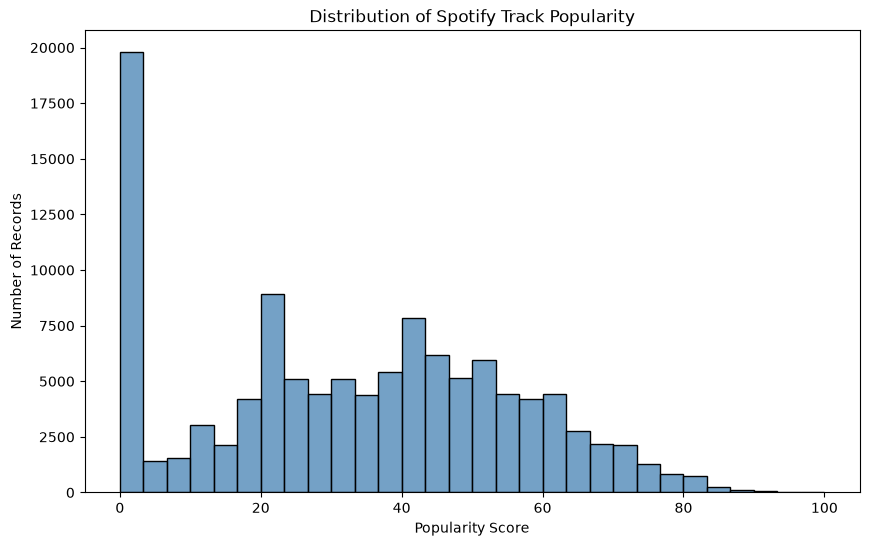

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_clean,
    x="popularity",
    bins=30,
    color="steelblue"
)

plt.title("Distribution of Spotify Track Popularity")
plt.xlabel("Popularity Score")
plt.ylabel("Number of Records")

plt.show()

### Popularity Distribution Observations

The histogram shows that the dataset contains more tracks with low or moderate popularity scores than highly popular ones. One of the most noticeable features is the large concentration of tracks with popularity close to zero, while tracks with popularity above 80 are relatively rare. This is consistent with the average popularity score of approximately 33.24. However, since the dataset contains almost exactly 1,000 records per genre and some tracks appear multiple times, this distribution may not accurately represent the popularity of all songs on Spotify.

### Danceability vs. Popularity

This visualization explores whether songs with higher danceability scores tend to have higher popularity scores.

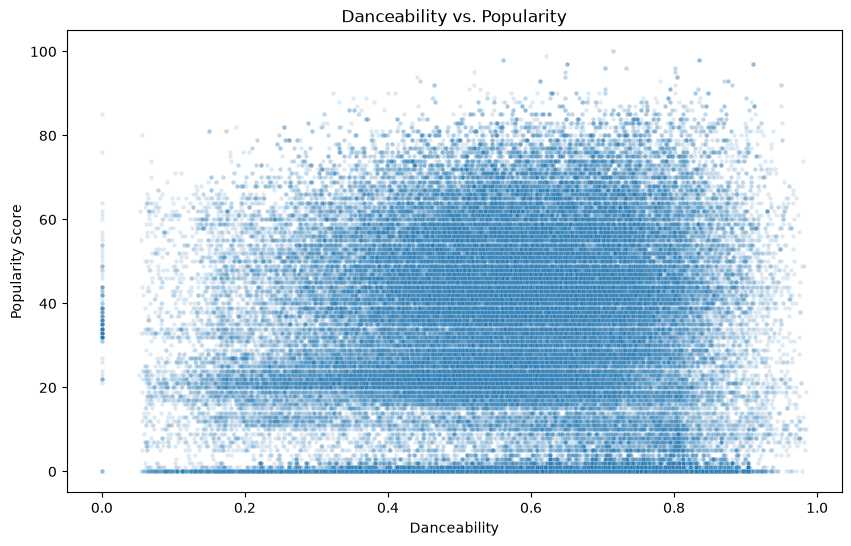

In [25]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="danceability",
    y="popularity",
    alpha=0.15,
    s=10
)

plt.title("Danceability vs. Popularity")
plt.xlabel("Danceability")
plt.ylabel("Popularity Score")

plt.show()

In [26]:
correlation = df_clean["danceability"].corr(
    df_clean["popularity"]
)

print("Correlation:", round(correlation, 3))

Correlation: 0.035


### Danceability vs. Popularity Observations

The scatter plot shows that there is almost no linear relationship between danceability and popularity. The correlation coefficient was only 0.035, which is really close to zero. Even songs with high danceability scores had very different popularity levels, ranging from nearly zero to almost 100. This suggests that danceability alone is not a strong indicator of a song's popularity. However, this does not necessarily mean that danceability has no influence, since other factors such as genre or artist recognition could also play a role.

### Popularity Across Music Genres

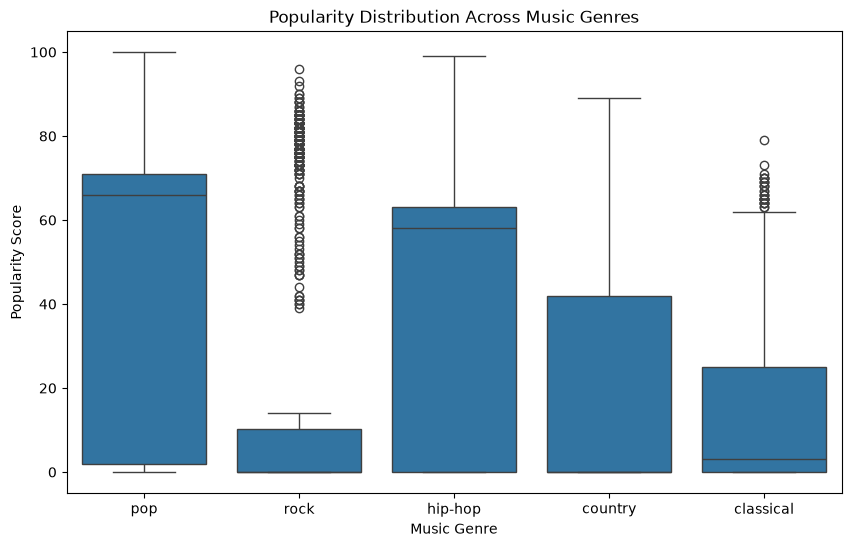

In [27]:
genres = ["pop", "rock", "hip-hop", "country", "classical"]

genre_data = df_clean[
    df_clean["track_genre"].isin(genres)
]

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=genre_data,
    x="track_genre",
    y="popularity",
    order=genres
)

plt.title("Popularity Distribution Across Music Genres")
plt.xlabel("Music Genre")
plt.ylabel("Popularity Score")

plt.show()

### Observations

The box plot shows noticeable differences in popularity across the five selected genres. Pop and hip-hop had the highest median popularity scores, at approximately 66 and 58, while rock, country, and classical had much lower medians. One interesting observation was that rock contained many outliers with high popularity scores, even though most of its records were concentrated almost at zero. This suggests that popularity distributions vary considerably depending on the music genre. Compared to the very weak correlation between danceability and popularity, genre differences appear more noticeable in this initial exploration. However, these results do not necessarily represent the entire Spotify platform, since the dataset appears to have been sampled equally across genres.

In [28]:
# Percentage of tracks with popularity equal to zero
zero_percentage = (df_clean["popularity"] == 0).mean() * 100

print(f"Tracks with zero popularity: {zero_percentage:.2f}%")

Tracks with zero popularity: 14.05%


## Dataset Quirks and Limitations

During the initial exploration, I noticed several characteristics that could affect future analyses. First, the dataset contains 114 music genres, with almost exactly 1,000 records per genre. This suggests that the data may have been collected using a balanced sampling method rather than representing the actual distribution of music on Spotify.

Another important observation was the presence of 42,259 repeated track IDs. After inspecting some examples, I noticed that the same songs could appear under multiple genres. I decided to keep these records for now, but this could influence statistical results by giving certain songs more weight.

Additionally, approximately 14.05% of the records have a popularity score of zero. This does not necessarily mean that these songs have never been streamed, since the popularity score is not a direct measurement of total streams.

Finally, the dataset does not provide information about marketing, playlist exposure, or artist recognition, which could also influence a song's success. Because of these limitations, I cannot assume that audio characteristics alone determine whether a song becomes popular.